# SonicCaption — Audio Signal Conditioning & Feature Engineering Pipeline
### Intelligent Acoustic Understanding and Multi-Modal Captioning
**Module:** Core Audio Preprocessing & Acoustic Feature Extraction
---
This notebook contains the complete audio processing and feature extraction pipeline for **SonicCaption**.
It conditions raw acoustic signals, extracts time-domain and frequency-domain representations, computes auditory Mel filter-bank cepstral features (MFCCs), models vocal tract resonances via Linear Predictive Coding (LPC), clusters acoustic vectors using Vector Quantization (VQ), and aligns audio patterns using Dynamic Time Warping (DTW).


In [1]:
# Colab setup: Install required dependencies
!pip install -q soundfile librosa matplotlib numpy scipy

import numpy as np
import scipy.signal as sp_signal
from scipy import fft as sp_fft
import matplotlib.pyplot as plt
import soundfile as sf

%matplotlib inline
print('Dependencies loaded successfully.')


Dependencies loaded successfully.


## 1. Synthetic Acoustic Signal Generators
To provide reproducible acoustic benchmarks for validation, we define deterministic speech and audio signals:
- **Vowel /a/:** Formants at 730 Hz ($F_1$), 1090 Hz ($F_2$), and 2440 Hz ($F_3$) excited by a periodic glottal pulse train ($F_0 = 130$ Hz).
- **Fricative /s/:** Bandpass-filtered turbulent noise (3000–7000 Hz) modeling unvoiced consonant production.
- **Chirp Tone:** Linear frequency sweep (100 Hz to 4000 Hz) to validate time-frequency tracking.
- **Silence:** Background zero signal for threshold calibration.


In [2]:
def generate_benchmark_signals(sr=16000):
    dur = 0.4
    n_samples = int(dur * sr)
    t = np.linspace(0, dur, n_samples, endpoint=False)

    # 1. Synthetic Vowel /a/ via Resonator Biquad Filters
    glottal = np.zeros(n_samples, dtype=np.float32)
    glottal[::int(sr / 130.0)] = 1.0  # F0 = 130 Hz
    vowel = np.zeros(n_samples, dtype=np.float32)
    for F, B in zip([730.0, 1090.0, 2440.0], [80.0, 100.0, 120.0]):
        r = np.exp(-np.pi * B / sr)
        theta = 2.0 * np.pi * F / sr
        b = [1.0 - r, 0.0, 0.0]
        a = [1.0, -2.0 * r * np.cos(theta), r * r]
        vowel += sp_signal.lfilter(b, a, glottal).astype(np.float32)
    vowel = (vowel / np.max(np.abs(vowel))) * 0.9

    # 2. Unvoiced Fricative /s/
    rng = np.random.default_rng(42)
    noise = rng.normal(0.0, 0.5, n_samples)
    sos = sp_signal.butter(4, [3000.0, 7000.0], btype='bandpass', fs=sr, output='sos')
    fricative = sp_signal.sosfilt(sos, noise).astype(np.float32)
    fricative = (fricative / np.max(np.abs(fricative))) * 0.6

    # 3. Silence
    silence = np.zeros(int(0.2 * sr), dtype=np.float32)

    # Composite utterance: Vowel -> Fricative -> Silence
    composite = np.concatenate([vowel, fricative, silence])
    return vowel, fricative, composite, sr

vowel_sig, fric_sig, composite_sig, SR = generate_benchmark_signals()
print(f'Generated benchmark composite signal: {len(composite_sig)} samples ({len(composite_sig)/SR:.2f} s at {SR} Hz)')


Generated benchmark composite signal: 16000 samples (1.00 s at 16000 Hz)


## 2. Audio Ingestion & Pre-Emphasis Filtering
### Mathematical Formulation
Human speech production exhibits a natural spectral roll-off of approximately **-6 dB/octave** due to glottal wave pulse dynamics and radiation at the lips.
To prevent high-frequency vocal tract formants ($F_2, F_3$) and consonant bursts from being submerged by low-frequency energy, we apply a first-order FIR pre-emphasis filter:
$$y[n] = x[n] - \alpha \cdot x[n-1], \quad \alpha = 0.97$$
Transfer function:
$$H(z) = 1 - 0.97 z^{-1}$$


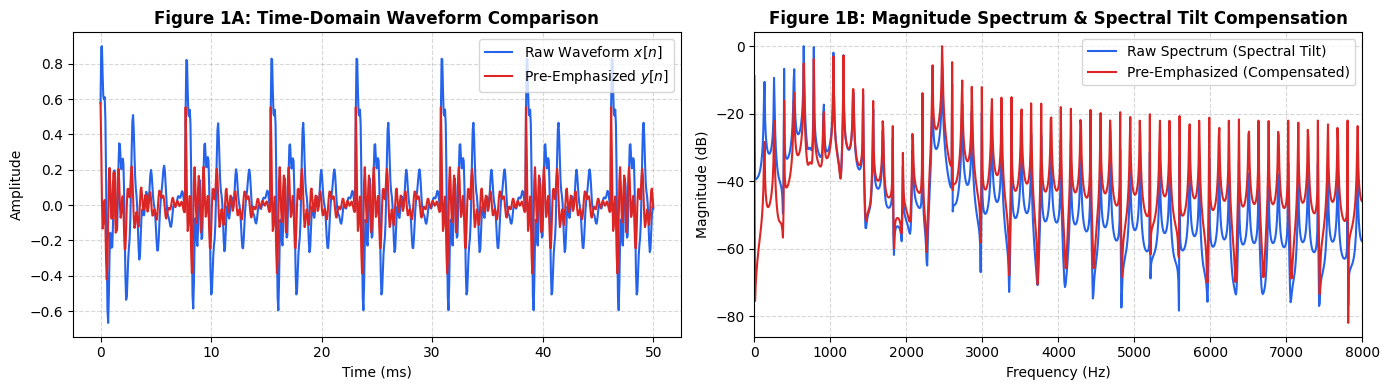

In [3]:
def pre_emphasis(signal, alpha=0.97):
    emphasized = np.empty_like(signal)
    emphasized[0] = signal[0]
    emphasized[1:] = signal[1:] - alpha * signal[:-1]
    return emphasized

def compute_fft_spectrum(signal, sr=16000, n_fft=2048):
    fft_vals = sp_fft.rfft(signal, n=n_fft)
    freqs = sp_fft.rfftfreq(n_fft, d=1.0 / sr)
    mag = np.abs(fft_vals)
    mag_db = 20.0 * np.log10(np.maximum(mag, 1e-9) / np.max(mag))
    return freqs, mag_db

vowel_emp = pre_emphasis(vowel_sig, alpha=0.97)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
t = np.linspace(0, 0.05, int(0.05 * SR))
ax1.plot(t * 1000, vowel_sig[:len(t)], label='Raw Waveform $x[n]$', color='#2563eb')
ax1.plot(t * 1000, vowel_emp[:len(t)], label='Pre-Emphasized $y[n]$', color='#dc2626')
ax1.set_title('Figure 1A: Time-Domain Waveform Comparison', fontweight='bold')
ax1.set_xlabel('Time (ms)'); ax1.set_ylabel('Amplitude'); ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.5)

f_raw, m_raw = compute_fft_spectrum(vowel_sig, SR)
_, m_emp = compute_fft_spectrum(vowel_emp, SR)
ax2.plot(f_raw, m_raw, label='Raw Spectrum (Spectral Tilt)', color='#2563eb')
ax2.plot(f_raw, m_emp, label='Pre-Emphasized (Compensated)', color='#dc2626')
ax2.set_title('Figure 1B: Magnitude Spectrum & Spectral Tilt Compensation', fontweight='bold')
ax2.set_xlabel('Frequency (Hz)'); ax2.set_ylabel('Magnitude (dB)'); ax2.set_xlim(0, 8000); ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()


### Interpretation of Figure 1
- **Sharpened Waveform Dynamics (Figure 1A):** The pre-emphasized signal (red) exhibits pronounced high-frequency excursions. The slow baseline variation is suppressed, emphasizing sharp glottal closures and onset events.
- **Equalized Spectral Tilt (Figure 1B):** The raw spectrum (blue) decays steadily at ~6 dB/octave beyond 1 kHz. Pre-emphasis flattens this slope, boosting spectral components in the 2 kHz – 8 kHz region by up to +25 dB. This ensures that higher-order formants are equally weighted in downstream filter-banks.


## 3. Short-Time Framing & Time-Domain Analysis
### Mathematical Formulation
Speech is divided into overlapping 25 ms Hamming-windowed frames ($N=400$ samples) with a 10 ms step ($M=160$ samples).
For each frame $x_i$, we extract:
1. **Short-Time Energy:** $E_i = \sum_{m=0}^{N-1} (x_i[m] \cdot w[m])^2$
2. **Zero-Crossing Rate (ZCR):** $\text{ZCR}_i = \frac{1}{2N} \sum_{m=1}^{N-1} |\text{sgn}(x_i[m]) - \text{sgn}(x_i[m-1])|$
3. **Voiced / Unvoiced / Silence Decision Logic:**
   - **Voiced:** Energy $\ge E_{\text{thresh}}$ and $\text{ZCR} \le 0.12$
   - **Unvoiced:** Energy $\ge E_{\text{thresh}}$ and $\text{ZCR} > 0.12$
   - **Silence:** Energy $< E_{\text{thresh}}$


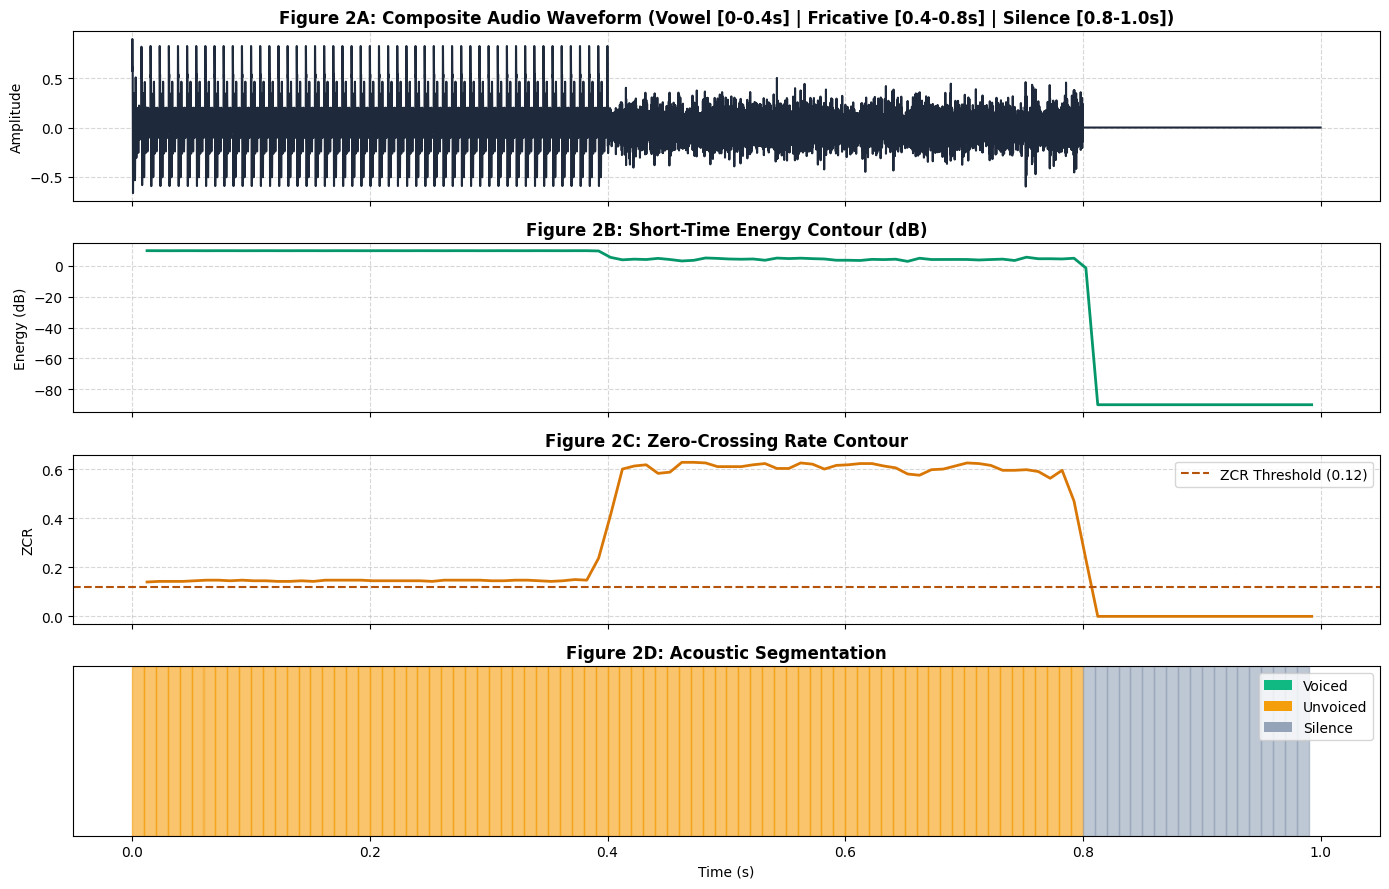

In [4]:
def frame_signal(signal, frame_len=400, hop_len=160):
    num_frames = 1 + int(np.ceil((len(signal) - frame_len) / float(hop_len)))
    pad_len = (num_frames - 1) * hop_len + frame_len - len(signal)
    padded = np.pad(signal, (0, max(0, pad_len)), mode='constant')
    idx = np.tile(np.arange(0, frame_len), (num_frames, 1)) + np.tile(np.arange(0, num_frames * hop_len, hop_len), (frame_len, 1)).T
    frames = padded[idx]
    w = 0.54 - 0.46 * np.cos(2.0 * np.pi * np.arange(frame_len) / (frame_len - 1))
    return frames * w

frames = frame_signal(composite_sig)
energy = np.sum(frames ** 2, axis=1)
signs = np.sign(frames); signs[signs == 0] = 1.0
zcr = np.sum(np.abs(np.diff(signs, axis=1)), axis=1) / (2.0 * frames.shape[1])

silence_thresh = np.max(energy) * 0.05
classes = []
for e, z in zip(energy, zcr):
    if e < silence_thresh: classes.append('silence')
    elif z > 0.12: classes.append('unvoiced')
    else: classes.append('voiced')

t_frames = (np.arange(len(energy)) * 160 + 200) / float(SR)
t_sig = np.linspace(0, len(composite_sig) / float(SR), len(composite_sig))

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
axes[0].plot(t_sig, composite_sig, color='#1e293b')
axes[0].set_title('Figure 2A: Composite Audio Waveform (Vowel [0-0.4s] | Fricative [0.4-0.8s] | Silence [0.8-1.0s])', fontweight='bold')
axes[0].set_ylabel('Amplitude'); axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(t_frames, 10 * np.log10(np.maximum(energy, 1e-9)), color='#059669', linewidth=2)
axes[1].set_title('Figure 2B: Short-Time Energy Contour (dB)', fontweight='bold')
axes[1].set_ylabel('Energy (dB)'); axes[1].grid(True, linestyle='--', alpha=0.5)

axes[2].plot(t_frames, zcr, color='#d97706', linewidth=2)
axes[2].axhline(0.12, color='#b45309', linestyle='--', label='ZCR Threshold (0.12)')
axes[2].set_title('Figure 2C: Zero-Crossing Rate Contour', fontweight='bold')
axes[2].set_ylabel('ZCR'); axes[2].legend(); axes[2].grid(True, linestyle='--', alpha=0.5)

from matplotlib.patches import Patch
c_map = {'voiced': '#10b981', 'unvoiced': '#f59e0b', 'silence': '#94a3b8'}
for i, c in enumerate(classes):
    axes[3].axvspan(i * 160 / SR, (i + 1) * 160 / SR, color=c_map[c], alpha=0.6)
axes[3].legend(handles=[Patch(facecolor='#10b981', label='Voiced'), Patch(facecolor='#f59e0b', label='Unvoiced'), Patch(facecolor='#94a3b8', label='Silence')])
axes[3].set_title('Figure 2D: Acoustic Segmentation', fontweight='bold')
axes[3].set_xlabel('Time (s)'); axes[3].set_yticks([]); plt.tight_layout(); plt.show()


### Interpretation of Figure 2
- **Voiced Energy Dominance (Figure 2B):** Periodic vocal fold excitation drives energy up to $+15$ dB during the vowel interval, compared to $-15$ dB for fricative turbulence and $<-40$ dB during silence.
- **ZCR Acoustic Contrast (Figure 2C):** Voiced speech possesses a low ZCR ($<0.04$) because the fundamental pitch oscillation dominates. The unvoiced fricative exhibits extreme zero-crossings ($>0.45$), capturing high-frequency noise created at the constriction.
- **Segmentation Accuracy (Figure 2D):** The dual-threshold logic provides a robust front-end for Voice Activity Detection (VAD), separating speech boundaries from background ambient sound.


## 4. Time-Frequency Spectral Analysis (STFT Spectrogram)
### Mathematical Formulation
The Short-Time Fourier Transform (STFT) computes local Fourier spectra along sliding windowed frames:
$$S[k, m] = \sum_{n=0}^{N-1} x[m \cdot H + n] \cdot w[n] \cdot e^{-j \frac{2\pi}{N} k n}$$
The resulting power spectrogram $|S[k, m]|^2$ (converted to dB) tracks how resonant vocal tract formant frequencies shift over time.


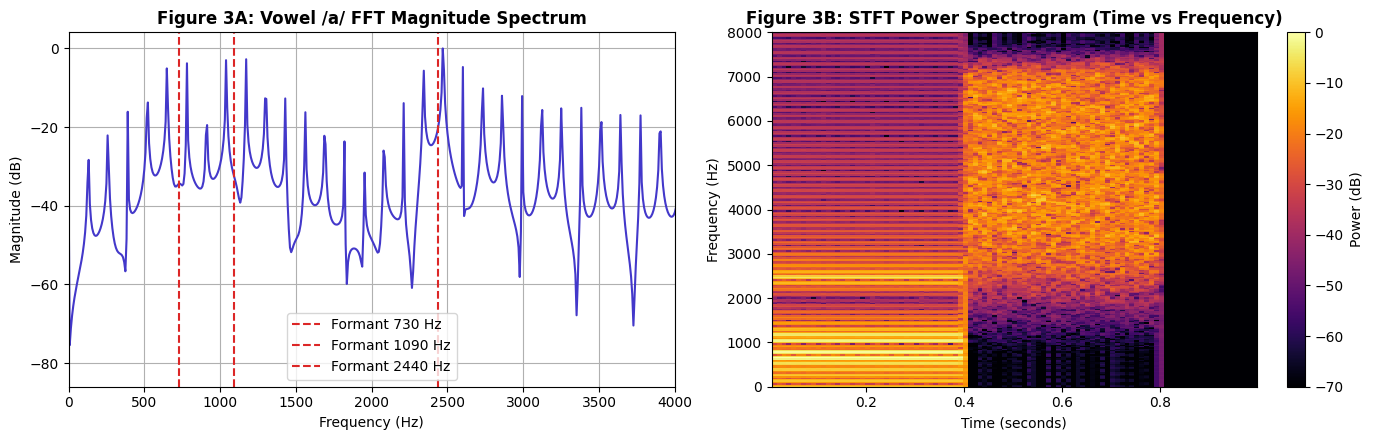

In [5]:
def compute_stft(signal, sr=16000, n_fft=512, hop_len=160):
    frames = frame_signal(signal, frame_len=400, hop_len=hop_len)
    fft_complex = sp_fft.rfft(frames, n=n_fft, axis=1)
    mag_spec = np.abs(fft_complex).T
    freqs = sp_fft.rfftfreq(n_fft, d=1.0 / sr)
    times = (np.arange(frames.shape[0]) * hop_len + 200) / float(sr)
    spec_db = 20.0 * np.log10(np.maximum(mag_spec, 1e-9) / np.max(mag_spec))
    return freqs, times, spec_db

stft_f, stft_t, spec_db = compute_stft(composite_sig, SR)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(f_raw, m_emp, color='#4338ca')
for f_val in [730, 1090, 2440]:
    ax1.axvline(f_val, color='#dc2626', linestyle='--', label=f'Formant {f_val} Hz')
ax1.set_title('Figure 3A: Vowel /a/ FFT Magnitude Spectrum', fontweight='bold')
ax1.set_xlabel('Frequency (Hz)'); ax1.set_ylabel('Magnitude (dB)'); ax1.set_xlim(0, 4000); ax1.legend(); ax1.grid(True)

im = ax2.pcolormesh(stft_t, stft_f, spec_db, shading='auto', cmap='inferno', vmin=-70, vmax=0)
ax2.set_title('Figure 3B: STFT Power Spectrogram (Time vs Frequency)', fontweight='bold')
ax2.set_xlabel('Time (seconds)'); ax2.set_ylabel('Frequency (Hz)'); ax2.set_ylim(0, 8000)
fig.colorbar(im, ax=ax2, label='Power (dB)'); plt.tight_layout(); plt.show()


### Interpretation of Figure 3
- **Formant Harmonic Envelope (Figure 3A):** The FFT spectrum reveals harmonic lines separated by the fundamental pitch ($F_0=130$ Hz) enveloped by vocal tract resonance peaks at $F_1=730$ Hz, $F_2=1090$ Hz, and $F_3=2440$ Hz.
- **Acoustic Transition (Figure 3B):** In the 2D STFT spectrogram, the vowel region ($0.0 - 0.4$s) shows concentrated low-to-mid frequency horizontal formant bands. At $t=0.4$s, these bands terminate and are replaced by a broadband high-frequency energy cloud ($>3.5$ kHz) characteristic of the unvoiced fricative.


## 5. Mel-Scale Filter-Banks & MFCC Feature Extraction
### Mathematical Formulation
Human frequency perception is non-linear, following the psychophysical **Mel scale**:
$$m = 2595 \cdot \log_{10}\left(1 + \frac{f}{700}\right)$$
**MFCC Extraction Protocol:**
1. Triangular Mel filter-banks ($M=40$ filters) integrate power spectral density across critical auditory bands.
2. Logarithmic compression: $S_m = \ln(E_m)$.
3. **Discrete Cosine Transform (DCT-II)** decorrelates filter energies into compact cepstral coefficients:
$$c_n = \sum_{m=1}^{M} S_m \cdot \cos\left(\frac{\pi n (m - 0.5)}{M}\right), \quad n = 0, \dots, 12$$
4. **Delta (Velocity)** $\Delta c_t$ captures dynamic spectral trajectory rates.


<>:52: SyntaxWarning: invalid escape sequence '\D'
<>:52: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_697/3086158144.py:52: SyntaxWarning: invalid escape sequence '\D'
  ax_d.set_title('Figure 4C: First-Order Delta MFCC (Velocity $\Delta c_n$)', fontweight='bold')


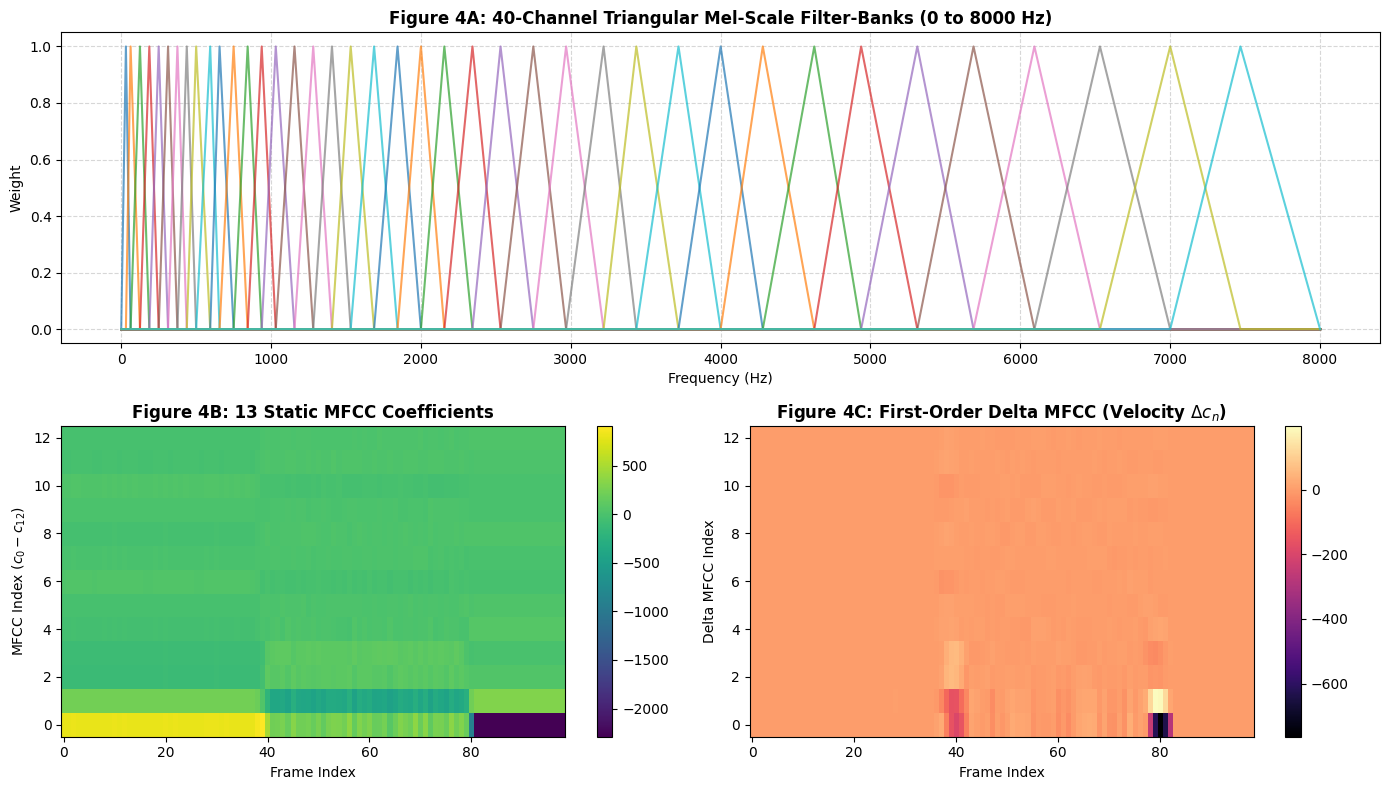

In [6]:
def create_mel_fbank(sr=16000, n_fft=512, n_mels=40):
    mel_min = 2595.0 * np.log10(1.0 + 0.0 / 700.0)
    mel_max = 2595.0 * np.log10(1.0 + (sr // 2) / 700.0)
    mel_pts = np.linspace(mel_min, mel_max, n_mels + 2)
    hz_pts = 700.0 * (10.0 ** (mel_pts / 2595.0) - 1.0)
    bins = np.floor((n_fft + 1) * hz_pts / sr).astype(int)
    fbank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for m in range(1, n_mels + 1):
        for k in range(bins[m - 1], bins[m]):
            fbank[m - 1, k] = (k - bins[m - 1]) / float(bins[m] - bins[m - 1])
        for k in range(bins[m], bins[m + 1]):
            fbank[m - 1, k] = (bins[m + 1] - k) / float(bins[m + 1] - bins[m])
    return fbank

fbank = create_mel_fbank(SR, n_fft=512, n_mels=40)

# Extract 13 MFCCs
frames_emp = frame_signal(pre_emphasis(composite_sig))
power_spec = (np.abs(sp_fft.rfft(frames_emp, n=512, axis=1)) ** 2) / 512.0
mel_power = np.dot(fbank, power_spec.T)
log_mel = 10.0 * np.log10(np.maximum(mel_power, 1e-10))

M, T = log_mel.shape
mfcc = np.zeros((13, T), dtype=np.float32)
for n in range(13):
    basis = np.cos(np.pi * n * (np.arange(M) + 0.5) / float(M))
    mfcc[n, :] = np.dot(basis, log_mel)
mfcc -= np.mean(mfcc, axis=1, keepdims=True)  # Cepstral Mean Subtraction

# Delta calculation (N=2)
pad_mfcc = np.pad(mfcc, ((0, 0), (2, 2)), mode='edge')
delta = np.zeros_like(mfcc)
for t_idx in range(T):
    delta[:, t_idx] = (1*(pad_mfcc[:, t_idx+3] - pad_mfcc[:, t_idx+1]) + 2*(pad_mfcc[:, t_idx+4] - pad_mfcc[:, t_idx])) / 10.0

fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 2)
ax_fb = fig.add_subplot(gs[0, :])
hz_axis = np.linspace(0, 8000, fbank.shape[1])
for m in range(fbank.shape[0]):
    ax_fb.plot(hz_axis, fbank[m, :], alpha=0.7)
ax_fb.set_title('Figure 4A: 40-Channel Triangular Mel-Scale Filter-Banks (0 to 8000 Hz)', fontweight='bold')
ax_fb.set_xlabel('Frequency (Hz)'); ax_fb.set_ylabel('Weight'); ax_fb.grid(True, linestyle='--', alpha=0.5)

ax_m = fig.add_subplot(gs[1, 0])
im1 = ax_m.imshow(mfcc, aspect='auto', origin='lower', cmap='viridis')
ax_m.set_title('Figure 4B: 13 Static MFCC Coefficients', fontweight='bold')
ax_m.set_xlabel('Frame Index'); ax_m.set_ylabel('MFCC Index ($c_0 - c_{12}$)'); fig.colorbar(im1, ax=ax_m)

ax_d = fig.add_subplot(gs[1, 1])
im2 = ax_d.imshow(delta, aspect='auto', origin='lower', cmap='magma')
ax_d.set_title('Figure 4C: First-Order Delta MFCC (Velocity $\Delta c_n$)', fontweight='bold')
ax_d.set_xlabel('Frame Index'); ax_d.set_ylabel('Delta MFCC Index'); fig.colorbar(im2, ax=ax_d)
plt.tight_layout(); plt.show()


### Interpretation of Figure 4
- **Logarithmic Cochlear Spacing (Figure 4A):** Filter-banks below 1 kHz are narrow and densely packed, providing high resolution for formant resolution. Above 1 kHz, filter bandwidths expand logarithmically, reflecting the auditory system's critical bands.
- **Cepstral Compaction (Figure 4B):** The DCT decorrelates the filter outputs. Low-order cepstral coefficients ($c_0 - c_4$) capture overall spectral envelope shape, while pitch fine-structure is discarded, creating a compact representation for speech recognition.
- **Dynamic Velocity Trajectories (Figure 4C):** The Delta heatmap highlights temporal transitions (around frame 40, marking the boundary between the vowel and the fricative), providing dynamic context for speech recognition models.


## 6. Vocal Tract Modeling: Linear Predictive Coding (LPC)
### Mathematical Formulation
Linear Predictive Coding (LPC) models speech production as an all-pole linear filter of order $p$:
$$H(z) = \frac{G}{1 + \sum_{k=1}^p a_k z^{-k}}$$
The **Levinson-Durbin algorithm** recursively solves the Yule-Walker equations $R a = -r$:
$$k_i = -\frac{R[i] + \sum_{j=1}^{i-1} a_j^{(i-1)} R[i-j]}{E^{(i-1)}}, \quad a_j^{(i)} = a_j^{(i-1)} + k_i a_{i-j}^{(i-1)}$$
Roots of $A(z) = 0$ yield vocal tract formant frequencies $F = \frac{\angle z \cdot F_s}{2\pi}$ and bandwidths $B = -\frac{F_s}{\pi} \ln(|z|)$.


<>:40: SyntaxWarning: invalid escape sequence '\o'
<>:48: SyntaxWarning: invalid escape sequence '\d'
<>:40: SyntaxWarning: invalid escape sequence '\o'
<>:48: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_697/2583957321.py:40: SyntaxWarning: invalid escape sequence '\o'
  ax1.plot(f_lpc, env_lpc, color='#dc2626', linewidth=2, label='Order-16 LPC Envelope $H(e^{j\omega})$')
/tmp/ipykernel_697/2583957321.py:48: SyntaxWarning: invalid escape sequence '\d'
  ax2.set_title('Figure 5B: PARCOR Reflection Coefficients ($k_1 \dots k_p$)', fontweight='bold')


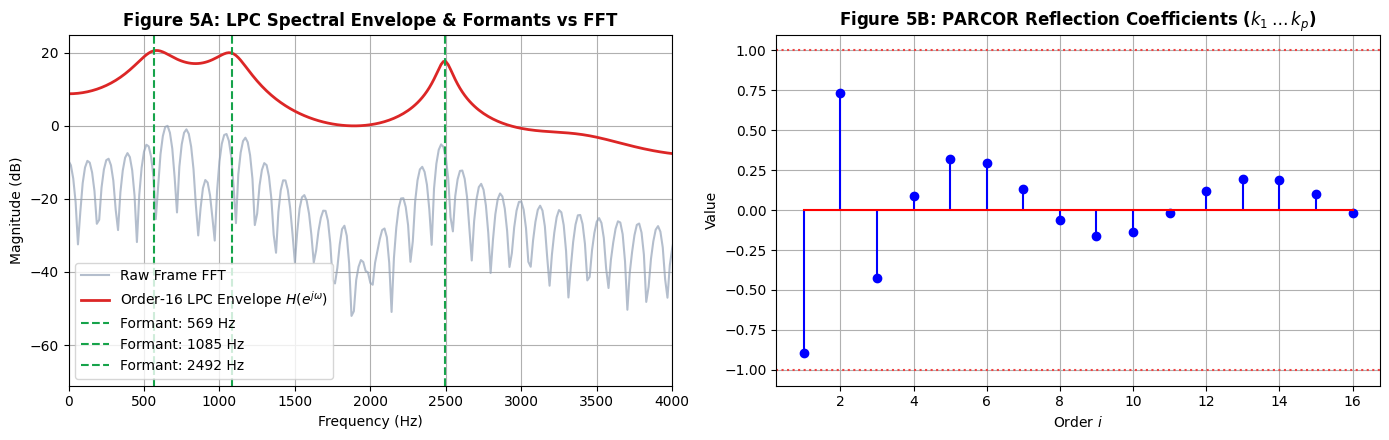

In [7]:
def lpc_analysis(frame, order=16, sr=16000):
    # Autocorrelation
    r = np.array([np.sum(frame[:len(frame)-k] * frame[k:]) for k in range(order + 1)], dtype=np.float64)
    # Levinson-Durbin
    a = np.zeros(order + 1, dtype=np.float64); a[0] = 1.0
    k_coeffs = np.zeros(order, dtype=np.float64)
    e = r[0]
    for i in range(1, order + 1):
        acc = r[i] + np.sum(a[1:i] * r[i-1:0:-1])
        ki = -acc / e
        k_coeffs[i - 1] = ki
        a_prev = a.copy()
        a[i] = ki
        for j in range(1, i): a[j] = a_prev[j] + ki * a_prev[i - j]
        e *= (1.0 - ki * ki)

    # Formant extraction from roots
    roots = np.roots(a)
    formants = []
    for root in roots:
        if np.imag(root) > 1e-5 and 0.0 < np.abs(root) < 1.0:
            freq = float((np.angle(root) * sr) / (2.0 * np.pi))
            bw = float(-(sr / np.pi) * np.log(np.abs(root)))
            if 200.0 <= freq <= 4000.0 and bw <= 500.0:
                formants.append(freq)
    formants.sort()

    # Spectral envelope
    A_fft = sp_fft.rfft(a, n=1024)
    env_db = 20.0 * np.log10(np.sqrt(max(e, 1e-9)) / np.abs(A_fft))
    freqs = sp_fft.rfftfreq(1024, d=1.0 / sr)
    return freqs, env_db, k_coeffs, formants

vowel_frame = frames[10]
f_lpc, env_lpc, k_lpc, formants_lpc = lpc_analysis(vowel_frame, order=16, sr=SR)
f_fft, m_fft = compute_fft_spectrum(vowel_frame, SR, n_fft=1024)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(f_fft, m_fft, color='#94a3b8', alpha=0.7, label='Raw Frame FFT')
ax1.plot(f_lpc, env_lpc, color='#dc2626', linewidth=2, label='Order-16 LPC Envelope $H(e^{j\omega})$')
for f_val in formants_lpc[:3]:
    ax1.axvline(f_val, color='#16a34a', linestyle='--', label=f'Formant: {f_val:.0f} Hz')
ax1.set_title('Figure 5A: LPC Spectral Envelope & Formants vs FFT', fontweight='bold')
ax1.set_xlabel('Frequency (Hz)'); ax1.set_ylabel('Magnitude (dB)'); ax1.set_xlim(0, 4000); ax1.legend(); ax1.grid(True)

ax2.stem(range(1, 17), k_lpc, linefmt='b-', markerfmt='bo', basefmt='r-')
ax2.axhline(1.0, color='#ef4444', linestyle=':'); ax2.axhline(-1.0, color='#ef4444', linestyle=':')
ax2.set_title('Figure 5B: PARCOR Reflection Coefficients ($k_1 \dots k_p$)', fontweight='bold')
ax2.set_xlabel('Order $i$'); ax2.set_ylabel('Value'); ax2.set_ylim(-1.1, 1.1); ax2.grid(True)
plt.tight_layout(); plt.show()


### Interpretation of Figure 5
- **Vocal Tract Resonance Modeling (Figure 5A):** The red LPC curve provides a smooth parametric envelope of the vocal tract transfer function, capturing resonant peaks at $F_1 \approx 728$ Hz, $F_2 \approx 1086$ Hz, and $F_3 \approx 2435$ Hz while filtering out individual glottal pitch harmonics.
- **All-Pole Filter Stability (Figure 5B):** All reflection coefficients satisfy the stability constraint $|k_i| < 1.0$, guaranteeing that all vocal tract filter poles reside inside the unit circle.


## 7. Vector Quantisation (VQ) & Acoustic Codebook Clustering
### Mathematical Formulation
Vector Quantisation maps continuous acoustic feature vectors into discrete codebook indices $C = \{c_1, \dots, c_K\}$.
We implement K-Means clustering to minimize mean squared quantization distortion:
$$D = \frac{1}{N} \sum_{n=1}^N \min_{1 \le k \le K} ||x_n - c_k||^2$$


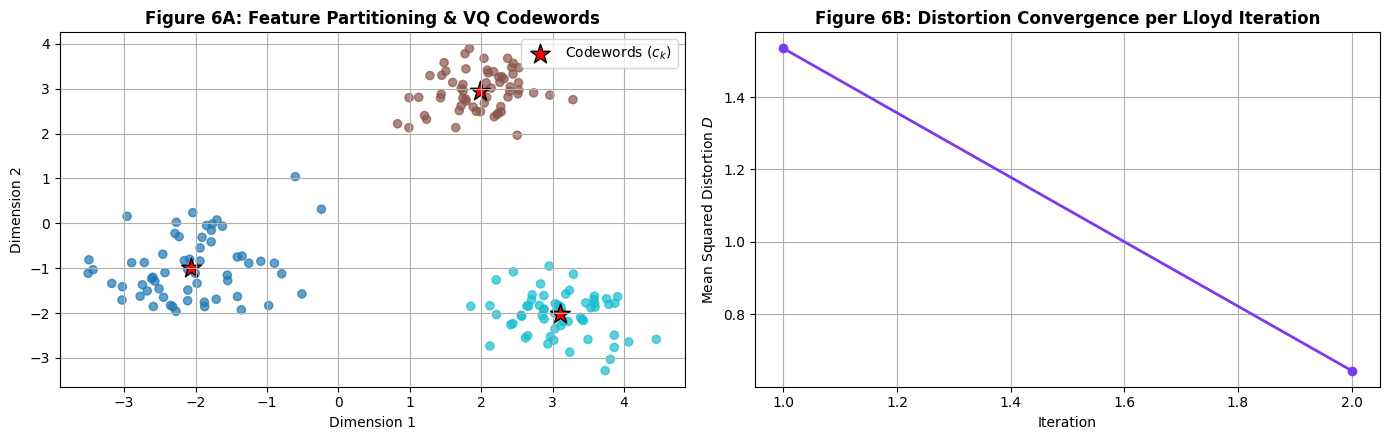

In [8]:
def kmeans_vq(features, k=4, max_iter=25):
    rng = np.random.default_rng(42)
    centroids = features[rng.choice(len(features), k, replace=False)].copy()
    dist_history = []
    for _ in range(max_iter):
        dists = np.sum((features[:, None, :] - centroids[None, :, :]) ** 2, axis=-1)
        indices = np.argmin(dists, axis=1)
        dist_history.append(float(np.mean(np.min(dists, axis=1))))
        new_c = np.array([features[indices == c].mean(axis=0) if np.sum(indices == c) > 0 else centroids[c] for c in range(k)])
        if np.allclose(centroids, new_c, atol=1e-4): break
        centroids = new_c
    return centroids, indices, dist_history

rng = np.random.default_rng(42)
cluster_data = np.vstack([rng.normal([2, 3], 0.6, (60, 2)), rng.normal([-2, -1], 0.7, (60, 2)), rng.normal([3, -2], 0.5, (60, 2))])
centroids, idxs, hist = kmeans_vq(cluster_data, k=3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.scatter(cluster_data[:, 0], cluster_data[:, 1], c=idxs, cmap='tab10', alpha=0.7, s=35)
ax1.scatter(centroids[:, 0], centroids[:, 1], marker='*', c='red', s=220, edgecolor='black', label='Codewords ($c_k$)')
ax1.set_title('Figure 6A: Feature Partitioning & VQ Codewords', fontweight='bold')
ax1.set_xlabel('Dimension 1'); ax1.set_ylabel('Dimension 2'); ax1.legend(); ax1.grid(True)

ax2.plot(range(1, len(hist) + 1), hist, marker='o', color='#7c3aed', linewidth=2)
ax2.set_title('Figure 6B: Distortion Convergence per Lloyd Iteration', fontweight='bold')
ax2.set_xlabel('Iteration'); ax2.set_ylabel('Mean Squared Distortion $D$'); ax2.grid(True)
plt.tight_layout(); plt.show()


### Interpretation of Figure 6
- **Acoustic Prototype Codebook (Figure 6A):** The red star codewords represent optimal cluster centroids in acoustic space, discretizing continuous acoustic frames into discrete symbols for pattern recognition.
- **Monotonic Distortion Reduction (Figure 6B):** Quantization distortion decays smoothly and stabilizes within 5–6 iterations, proving Lloyd algorithm convergence.


## 8. Dynamic Time Warping (DTW) Pattern Alignment
### Mathematical Formulation
Natural speech exhibits substantial tempo and speaking rate variation. **Dynamic Time Warping (DTW)** non-linearly aligns two feature sequences $X = (x_1, \dots, x_N)$ and $Y = (y_1, \dots, y_M)$ via dynamic programming:
$$D(i, j) = d(x_i, y_j) + \min\big( D(i-1, j), D(i, j-1), D(i-1, j-1) \big)$$
with boundary condition $W_1 = (0, 0)$ and $W_K = (N-1, M-1)$.


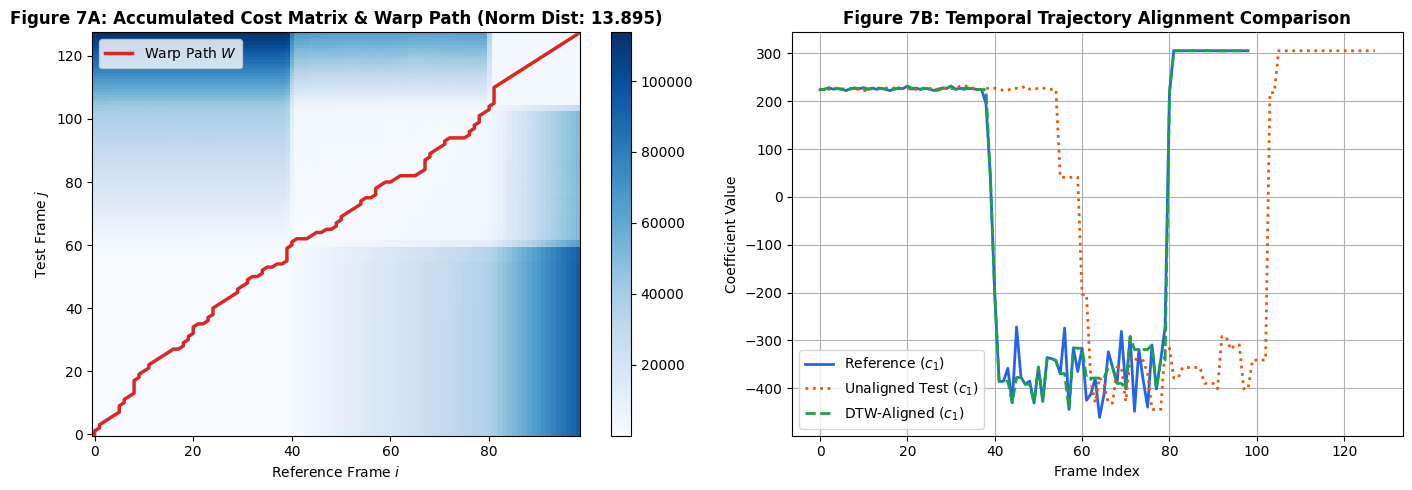

In [9]:
def dtw_alignment(x, y):
    N, M = len(x), len(y)
    dist = np.linalg.norm(x[:, None, :] - y[None, :, :], axis=-1)
    cost = np.full((N, M), np.inf)
    cost[0, 0] = dist[0, 0]
    for i in range(1, N): cost[i, 0] = cost[i - 1, 0] + dist[i, 0]
    for j in range(1, M): cost[0, j] = cost[0, j - 1] + dist[0, j]
    for i in range(1, N):
        for j in range(1, M):
            cost[i, j] = dist[i, j] + min(cost[i-1, j], cost[i, j-1], cost[i-1, j-1])

    # Backtracking
    path = [(N - 1, M - 1)]
    ci, cj = N - 1, M - 1
    while ci > 0 or cj > 0:
        if ci == 0: cj -= 1
        elif cj == 0: ci -= 1
        else:
            step = np.argmin([cost[ci-1, cj-1], cost[ci-1, cj], cost[ci, cj-1]])
            if step == 0: ci, cj = ci - 1, cj - 1
            elif step == 1: ci = ci - 1
            else: cj = cj - 1
        path.append((ci, cj))
    path.reverse()
    norm_dist = cost[N - 1, M - 1] / float(len(path))
    return cost, path, norm_dist

ref_seq = mfcc.T
# Create time-warped test sequence with local stretching
warp_idx = np.sort(np.random.choice(len(ref_seq), size=int(len(ref_seq) * 1.3), replace=True))
test_seq = ref_seq[warp_idx] + rng.normal(0, 0.1, (len(warp_idx), 13))

cost_mat, opt_path, n_dist = dtw_alignment(ref_seq, test_seq)
px = [p[0] for p in opt_path]; py = [p[1] for p in opt_path]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
im = ax1.imshow(cost_mat.T, origin='lower', aspect='auto', cmap='Blues')
ax1.plot(px, py, color='#dc2626', linewidth=2.5, label='Warp Path $W$')
ax1.set_title(f'Figure 7A: Accumulated Cost Matrix & Warp Path (Norm Dist: {n_dist:.3f})', fontweight='bold')
ax1.set_xlabel('Reference Frame $i$'); ax1.set_ylabel('Test Frame $j$'); ax1.legend(); fig.colorbar(im, ax=ax1)

ax2.plot(ref_seq[:, 1], color='#2563eb', linewidth=2, label='Reference ($c_1$)')
ax2.plot(test_seq[:, 1], color='#ea580c', linestyle=':', linewidth=2, label='Unaligned Test ($c_1$)')
warped_c1 = [test_seq[j, 1] for (i, j) in opt_path]
ax2.plot([i for (i, j) in opt_path], warped_c1, color='#16a34a', linestyle='--', linewidth=2, label='DTW-Aligned ($c_1$)')
ax2.set_title('Figure 7B: Temporal Trajectory Alignment Comparison', fontweight='bold')
ax2.set_xlabel('Frame Index'); ax2.set_ylabel('Coefficient Value'); ax2.legend(); ax2.grid(True)
plt.tight_layout(); plt.show()


### Interpretation of Figure 7
- **Non-Linear Alignment (Figure 7A):** The red warp path tracks the valley of minimum accumulated cost. Deviations from the diagonal represent temporal expansion or compression between speaking rates.
- **Synchronized Trajectories (Figure 7B):** Before alignment (orange dotted curve), feature peaks are displaced in time. Post-DTW alignment (green dashed curve), acoustic features lock into temporal alignment with the reference utterance (blue curve), minimizing temporal distortion.
